# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [37]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [38]:
def get_random_images(filepath, n=1000):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [39]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [ ]:
def get_imdb_data(imdb_id):
    """Fetch and parse IMDB page data."""
    url = f'https://www.imdb.com/title/{imdb_id}/'
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}
    
    try:
        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.text, 'html.parser')
        script = soup.find('script', {'type': 'application/ld+json'})
        if not script:
            return None
        
        import json
        data = json.loads(script.string)
        
        # Extract and validate rating
        rating = data.get('aggregateRating', {}).get('ratingValue')
        if not rating:
            return None
            
        # Extract and validate date
        date_published = data.get('datePublished')
        if not date_published:
            return None
            
        # Extract and validate genres
        genres = data.get('genre', [])
        if not isinstance(genres, list) or len(genres) == 0:
            return None
        
        show_data = {
            'imdb_id': imdb_id,
            'title': data.get('name', ''),
            'rating': data.get('aggregateRating', {}).get('ratingValue', 0),
            'rating_count': data.get('aggregateRating', {}).get('ratingCount', 0),
            'content_rating': data.get('contentRating', ''),
            'date_published': data.get('datePublished', ''),
            'genres': data.get('genre', []),
        }
        
        return show_data
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [41]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [42]:
def create_dataset(image_folder):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            color_features = extract_color_features(img_path)

            if color_features is not None:
                # Extract year from date_published
                year = pd.to_datetime(show_data['date_published']).year
                
                # Get genres and create one-hot encoding
                genres = show_data['genres']
                
                # Combine all features
                combined_data = {
                    'imdb_id': imdb_id,
                    'r_mean': color_features[0],
                    'g_mean': color_features[1],
                    'b_mean': color_features[2],
                    'w_mean': color_features[3],
                    'rating': show_data['rating'],
                    'year': year,
                    'genres': genres
                }
                data.append(combined_data)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    
    # Create one-hot encoding for genres
    all_genres = []
    for genres in df['genres']:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create genre columns
    for genre in unique_genres:
        df[f'genre_{genre}'] = df['genres'].apply(lambda x: 1 if genre in x else 0)
    
    # Drop the original genres column
    df = df.drop('genres', axis=1)
    
    # Save dataset
    df.to_csv('combined_data.csv', index=False)
    
    return df

In [43]:
def perform_pca_analysis(df):
    """Perform PCA on features including metadata."""
    # Prepare feature matrix (exclude imdb_id)
    X = df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    return pca, X_pca, n_components, X.columns

In [44]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

In [45]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [46]:
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [47]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [48]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 2D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(132)
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(133)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [49]:
def analyze_clusters(X_pca, df, clustering_method='kmeans', n_clusters=3):
    """Analyze clusters based on all features."""
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
        
    # Add cluster labels to the dataframe
    df_analysis = df.copy()
    df_analysis['Cluster'] = labels
    
    # Analyze numerical features
    numerical_features = ['rating', 'year', 'r_mean', 'g_mean', 'b_mean', 'w_mean']
    cluster_stats = df_analysis.groupby('Cluster')[numerical_features].agg(['mean', 'std'])
    
    # Analyze genre distributions
    genre_columns = [col for col in df.columns if col.startswith('genre_')]
    genre_stats = df_analysis.groupby('Cluster')[genre_columns].mean()
    
    print("\nNumerical Feature Statistics by Cluster:")
    print(cluster_stats)
    print("\nGenre Distribution by Cluster:")
    print(genre_stats)
    
    return labels

In [50]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
combined_df = create_dataset(IMAGE_FOLDER)   

Step 1: Gathering data...


In [51]:
print("\nIMDB Data Sample:")
combined_df.head()


IMDB Data Sample:


,imdb_id,r_mean,g_mean,b_mean,w_mean,rating,year,genre_Action,genre_Adventure,genre_Animation,...,genre_News,genre_Reality-TV,genre_Romance,genre_Sci-Fi,genre_Short,genre_Sport,genre_Talk-Show,genre_Thriller,genre_War,genre_Western
0,tt0090396,149.694568,129.437513,115.696734,45.769469,6.9,1986.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,tt0404616,73.034253,65.858179,61.068904,34.772826,0.0,2002.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,tt0092455,82.768907,79.943944,76.659412,39.316831,8.7,1987.0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
3,tt0310455,91.365593,49.015399,48.309271,38.693807,8.6,2002.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,tt0775402,144.603090,129.748831,118.454175,40.214277,7.3,2006.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [52]:
# Perform PCA analysis
print("\nStep 2: Performing PCA analysis...")
pca, X_pca, n_components, feature_names = perform_pca_analysis(combined_df)


Step 2: Performing PCA analysis...


ValueError: Input X contains NaN.
PCA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
# Display PCA results
print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
print(evr)


Explained variance ratios:
                     Explained Variance Ratio
Principal Component                          
PC1                                  0.154813
PC2                                  0.093257
PC3                                  0.080426
PC4                                  0.071610
PC5                                  0.065014
PC6                                  0.063493
PC7                                  0.055328
PC8                                  0.051884
PC9                                  0.044587
PC10                                 0.042863
PC11                                 0.039205
PC12                                 0.036023
PC13                                 0.034694
PC14                                 0.028666
PC15                                 0.025237
PC16                                 0.023235
PC17                                 0.019760
PC18                                 0.014557
PC19                                 0.012392
PC20  

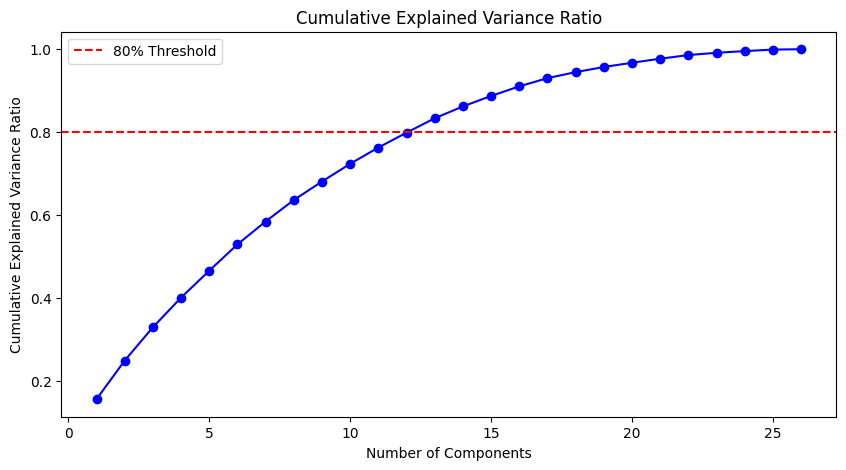

In [ ]:
plot_cumulative_variance(pca)

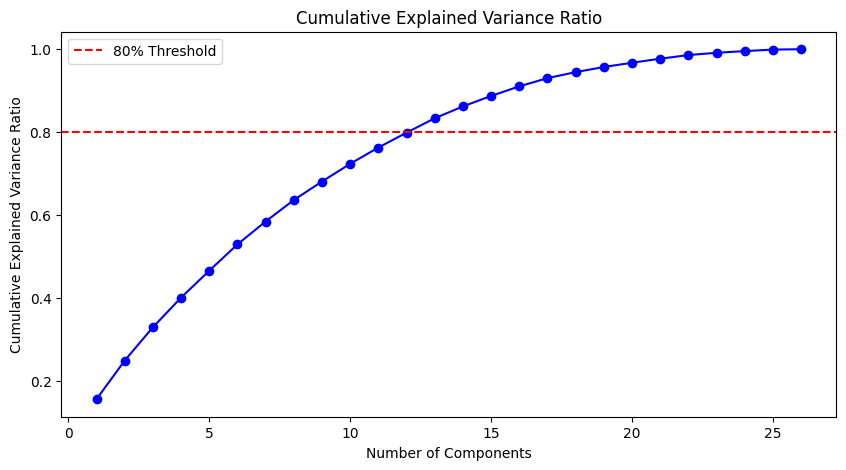

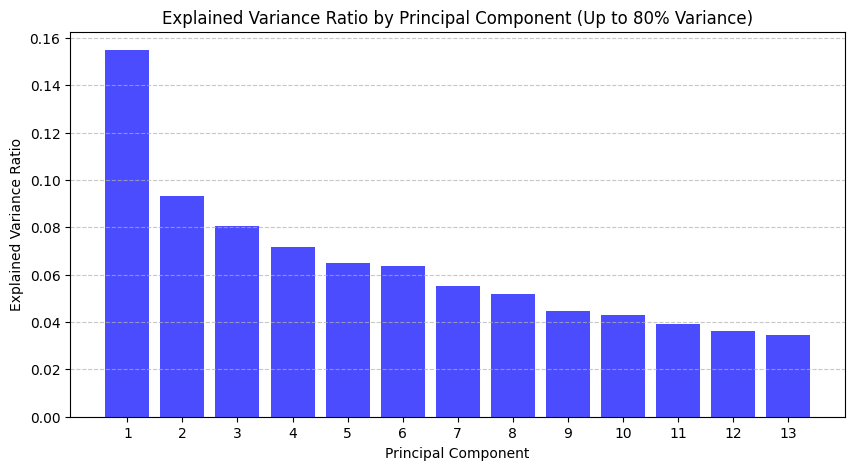

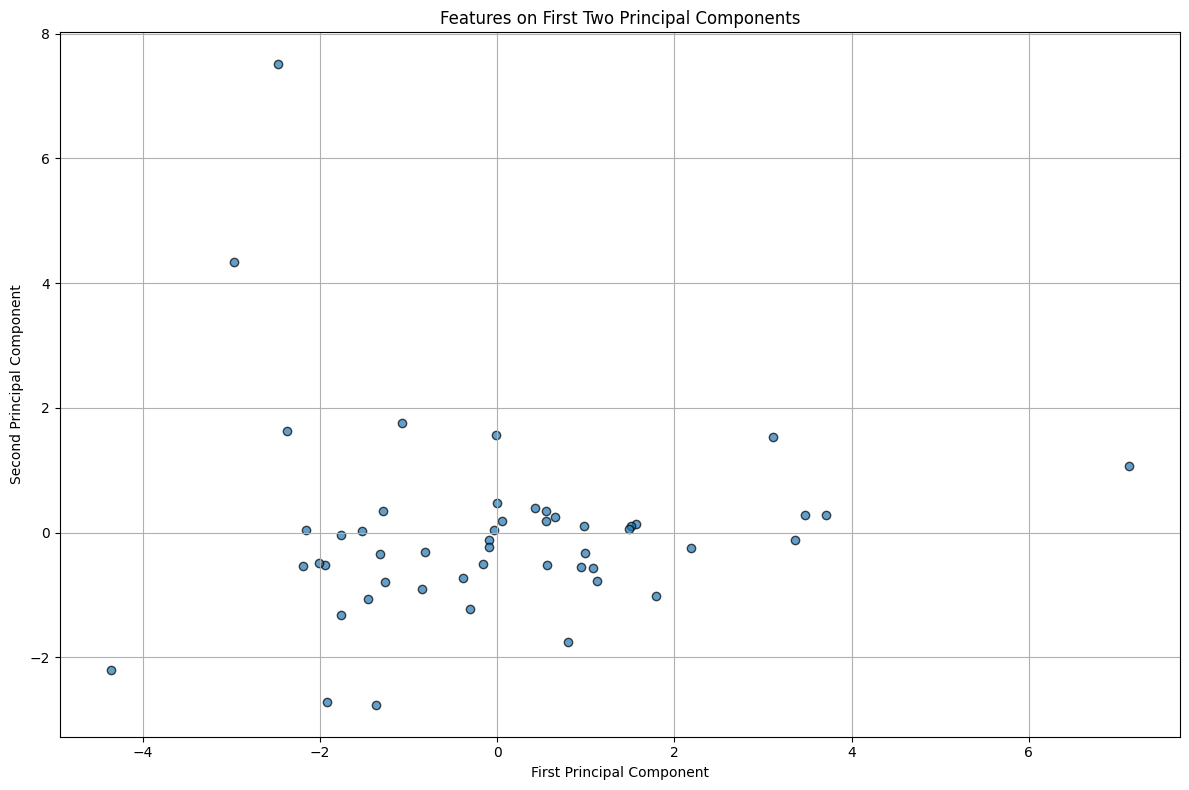

In [ ]:
# Plot PCA analysis
plot_cumulative_variance(pca)
plot_explained_variance(pca, n_components)
plot_pca_features(pca, X_pca, n_components)

In [ ]:
# Show feature loadings
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
print("\nFeature Loadings:")
print(loadings_df)
print("\nTop Feature Contributions to PC1:")
print(loadings_df.sort_values(by="PC1", ascending=False).head(10))


Feature Loadings:
                        PC1       PC2       PC3       PC4       PC5       PC6  \
r_mean             0.833575 -0.004085  0.012732  0.000692 -0.144432 -0.144509   
g_mean             0.898393 -0.007792 -0.117550  0.094353 -0.174996 -0.117801   
b_mean             0.779186  0.137571 -0.042749 -0.021867 -0.051771  0.036687   
w_mean             0.837290  0.081451  0.115811  0.070136 -0.081599  0.111811   
rating            -0.351059  0.031925 -0.290882  0.149061  0.397677  0.293566   
year               0.104418  0.336142  0.390763  0.235804 -0.085423 -0.335859   
genre_Action      -0.323146 -0.325405 -0.137451  0.062247 -0.067560  0.273034   
genre_Adventure   -0.289564 -0.464758 -0.235078  0.214504 -0.329455  0.403000   
genre_Animation    0.030368  0.036567  0.196455  0.103877  0.254808 -0.184555   
genre_Comedy      -0.122440 -0.117987  0.428747  0.226891  0.558956 -0.276275   
genre_Crime        0.441392 -0.017336 -0.295110  0.063162  0.113383 -0.109236   
genre_Doc


Step 3: Performing clustering analysis...


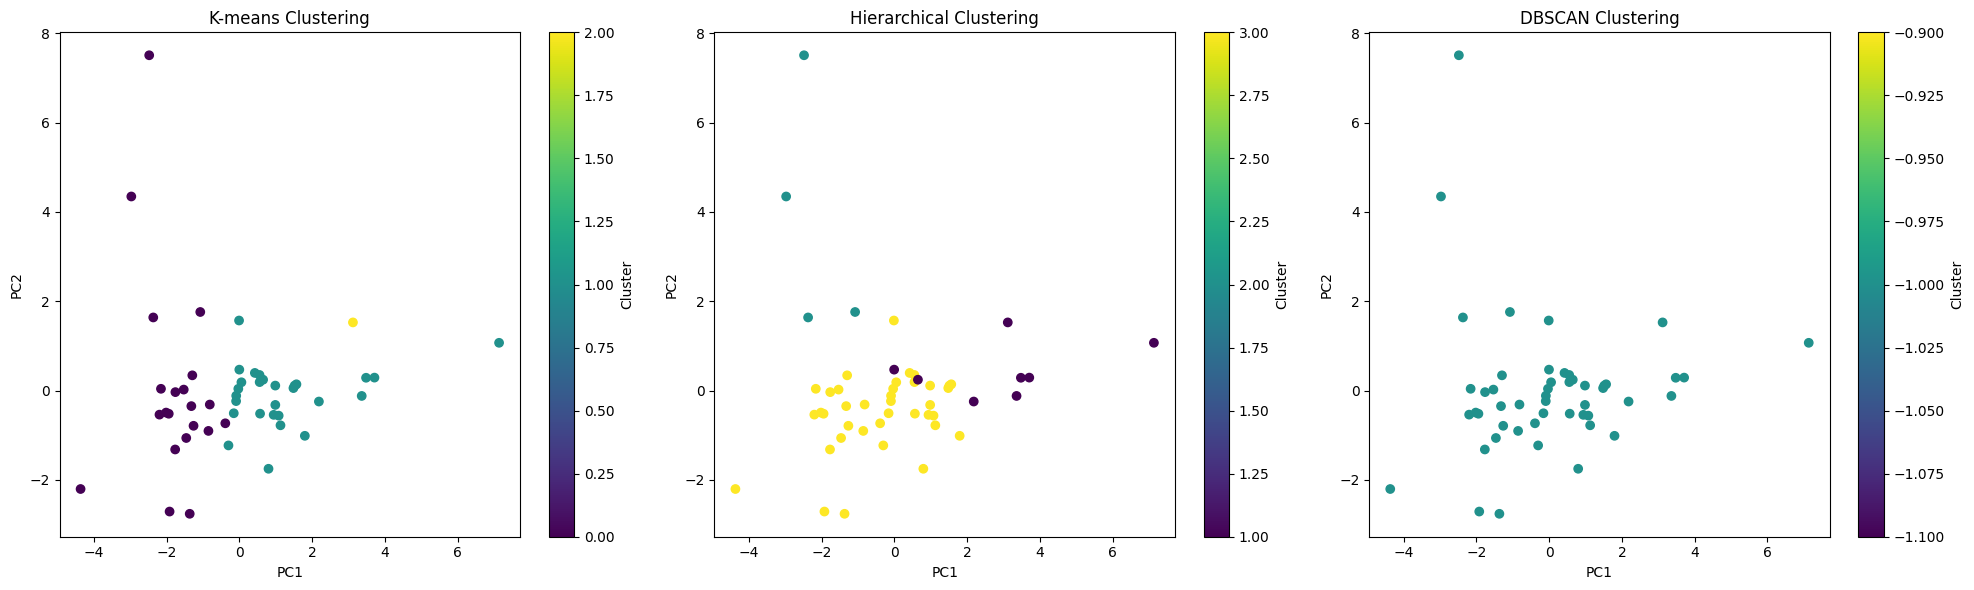

In [ ]:
# Perform clustering analysis
print("\nStep 3: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

In [ ]:
# Analyze clusters
print("\nStep 4: Analyzing clusters...")
labels = analyze_clusters(X_pca, combined_df, clustering_method='kmeans', n_clusters=3)


Step 4: Analyzing clusters...

Numerical Feature Statistics by Cluster:
           rating                   year                 r_mean             \
             mean       std         mean        std        mean        std   
Cluster                                                                      
0        6.279412  2.084398  1984.352941  16.030052  134.233810  41.697318   
1        7.200000  0.780110  1993.000000  13.453624   71.738947  27.997305   
2        7.400000       NaN  1997.000000        NaN  144.414076        NaN   

             g_mean                 b_mean                w_mean            
               mean        std        mean        std       mean       std  
Cluster                                                                     
0        118.068578  36.389086  107.330398  38.110652  43.313570  6.801470  
1         70.827852  28.430452   72.711800  42.630939  32.417130  7.445014  
2        128.176392        NaN  163.817934        NaN  64.613458       Na